In [1]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import os
from matplotlib.pyplot import *
import local


# Visual settings
%config InlineBackend.figure_format='retina'
%matplotlib inline

if '/Library/TeX/texbin/' not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + '/Library/TeX/texbin/'
    
# Latex font
plt.rc('font', **{'family': 'serif', 'serif': ['Computer Modern']})
plt.rc('text', usetex=True)


%matplotlib inline
%config InlineBackend.figure_format = 'retina'
from matplotlib import colors
#plt.rcParams['figure.figsize'] = [9,7]  # Adjust the size as needed for the plots
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# ==============================================================================
# 1. GLOBAL PARAMETERS & INITIALIZATION (Run this once at the top)
# ==============================================================================

# Background Cosmology
H0_km_s_Mpc = 68.465
Om_M = 0.29917
km_s_Mpc_to_eV = 2.13313e-35
H0_eV = H0_km_s_Mpc * km_s_Mpc_to_eV

# Injection Window
z_start = 60.0
z_end = 50.0
a_start = 1.0 / (1.0 + z_start)
a_end = 1.0 / (1.0 + z_end)

# Benchmark Model Parameters
logm = -30.5
xi_crit = 0.0163025        # Known xi_crit:    
                            #-30.6: 0.0227386,
                            #-30.5: 0.0163025,
                            #-30.4: 0.0118965
xi = 0.0042
frac = 1e-3
rho_phi_ini = frac

# Numerical Solver (IVP) Settings
n = 1
tf = 100
rtol = 1e-5
atol = 1e-7
eps = 1e-8

# Integration Grid and Initial Conditions
a = np.logspace(-6, 0, 2000)
z = 1.0 / a - 1.0
a_ini = a[0]
theta_ini = 0.01
bphi0_ini = theta_ini * tf
bphi1_ini = 0.0

print(f"Global Parameters Loaded (logm = {logm}, xi = {xi}, Frac = {frac})")

Global Parameters Loaded (logm = -30.5, xi = 0.0042, Frac = 0.001)


# $\rho_c(a)$ plots, varying $\xi$


From the CDM density continuity equation in the presence of an energy exchange:

$$\rho'_c + 3 \mathcal{H} \rho_c = - Q = -\mathcal{H} \xi \rho_c$$

it is straightforward to integrate, taking into account that the derivative is with respect to the conformal time $\tau$ and $\mathcal{H} = \frac{1}{a} \frac{da}{d\tau}$.

As a result:

$$\frac{d\rho_c}{\rho_c} = -(\xi + 3) \frac{da}{a}$$

$$\Downarrow$$

$$\rho_c (a) = \rho_{c, ini} \left(\frac{a}{a_{ini}}\right)^{-(\xi +3)}$$

Let's take $a_{ini} = a_{\rm CMB}$ as a reference.

However, the solution above holds only if $\xi \neq 0$ at all times. In our model, $\xi$ is a step function that is non-zero only for $a \in [a_{\rm start}, a_{\rm end}]$. Therefore, the equation must be integrated across three distinct intervals:
- **Interval 1:** from $a_{ini} = a_{\rm CMB} \rightarrow a_{\rm start}$, where $\xi = 0$;
- **Interval 2:** from $a_{\rm start} \rightarrow a_{\rm end}$, where $\xi \neq 0$;
- **Interval 3:** from $a_{\rm end} \rightarrow a_{\rm now}$, where $\xi = 0$ again.

In standard $\Lambda\text{CDM}$, $\xi = 0$ at all times, recovering the usual dilution $\rho_c \propto a^{-3}$.

We obtain the following piecewise solutions:

* **Interval 1 ($a \le a_{\rm start}$):**
  $$\rho_c(a) = \rho_c(a_{\rm CMB}) \left(\frac{a}{a_{\rm CMB}}\right)^{-3}$$

* **Interval 2 ($a_{\rm start} < a \le a_{\rm end}$):**
  $$\rho_c(a) = \rho_c(a_{\rm start}) \left(\frac{a}{a_{\rm start}}\right)^{-3-\xi} = \rho_c(a_{\rm CMB}) \left(\frac{a_{\rm start}}{a_{\rm CMB}}\right)^{-3} \left(\frac{a}{a_{\rm start}}\right)^{-3-\xi}$$

* **Interval 3 ($a > a_{\rm end}$):**
  $$\rho_c(a) = \rho_c(a_{\rm end}) \left(\frac{a}{a_{\rm end}}\right)^{-3} = \rho_c(a_{\rm CMB}) \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{-\xi} \left(\frac{a}{a_{\rm CMB}}\right)^{-3}$$

Therefore, the ratio $R(a) \equiv \frac{\rho_c(a)|_{\rm inj}}{\rho_c(a)|_{\Lambda\text{CDM}}}$ is simply given by:

* **Interval 1:**
  $$R(a) = 1$$

* **Interval 2:**
  $$R(a) = \left(\frac{a}{a_{\rm start}}\right)^{-\xi} = \left(\frac{1+z_{\rm start}}{1+z}\right)^{-\xi}$$

* **Interval 3:**
  $$R(a) = \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{-\xi} = \left(\frac{1+z_{\rm start}}{1+z_{\rm end}}\right)^{-\xi}$$

By choosing benchmark values $\tilde{\xi} = 10^3 \xi = 10 \implies \xi = 10^{-2}$, with $z_{\rm start} = 60$ and $z_{\rm end} = 50$, we obtain:

$$R_{\rm now} = \left(\frac{61}{51}\right)^{-0.01} \approx 0.998$$

Consequently, in this benchmark scenario, only $\sim 0.2\%$ of the dark matter energy is transferred to the axion sector.

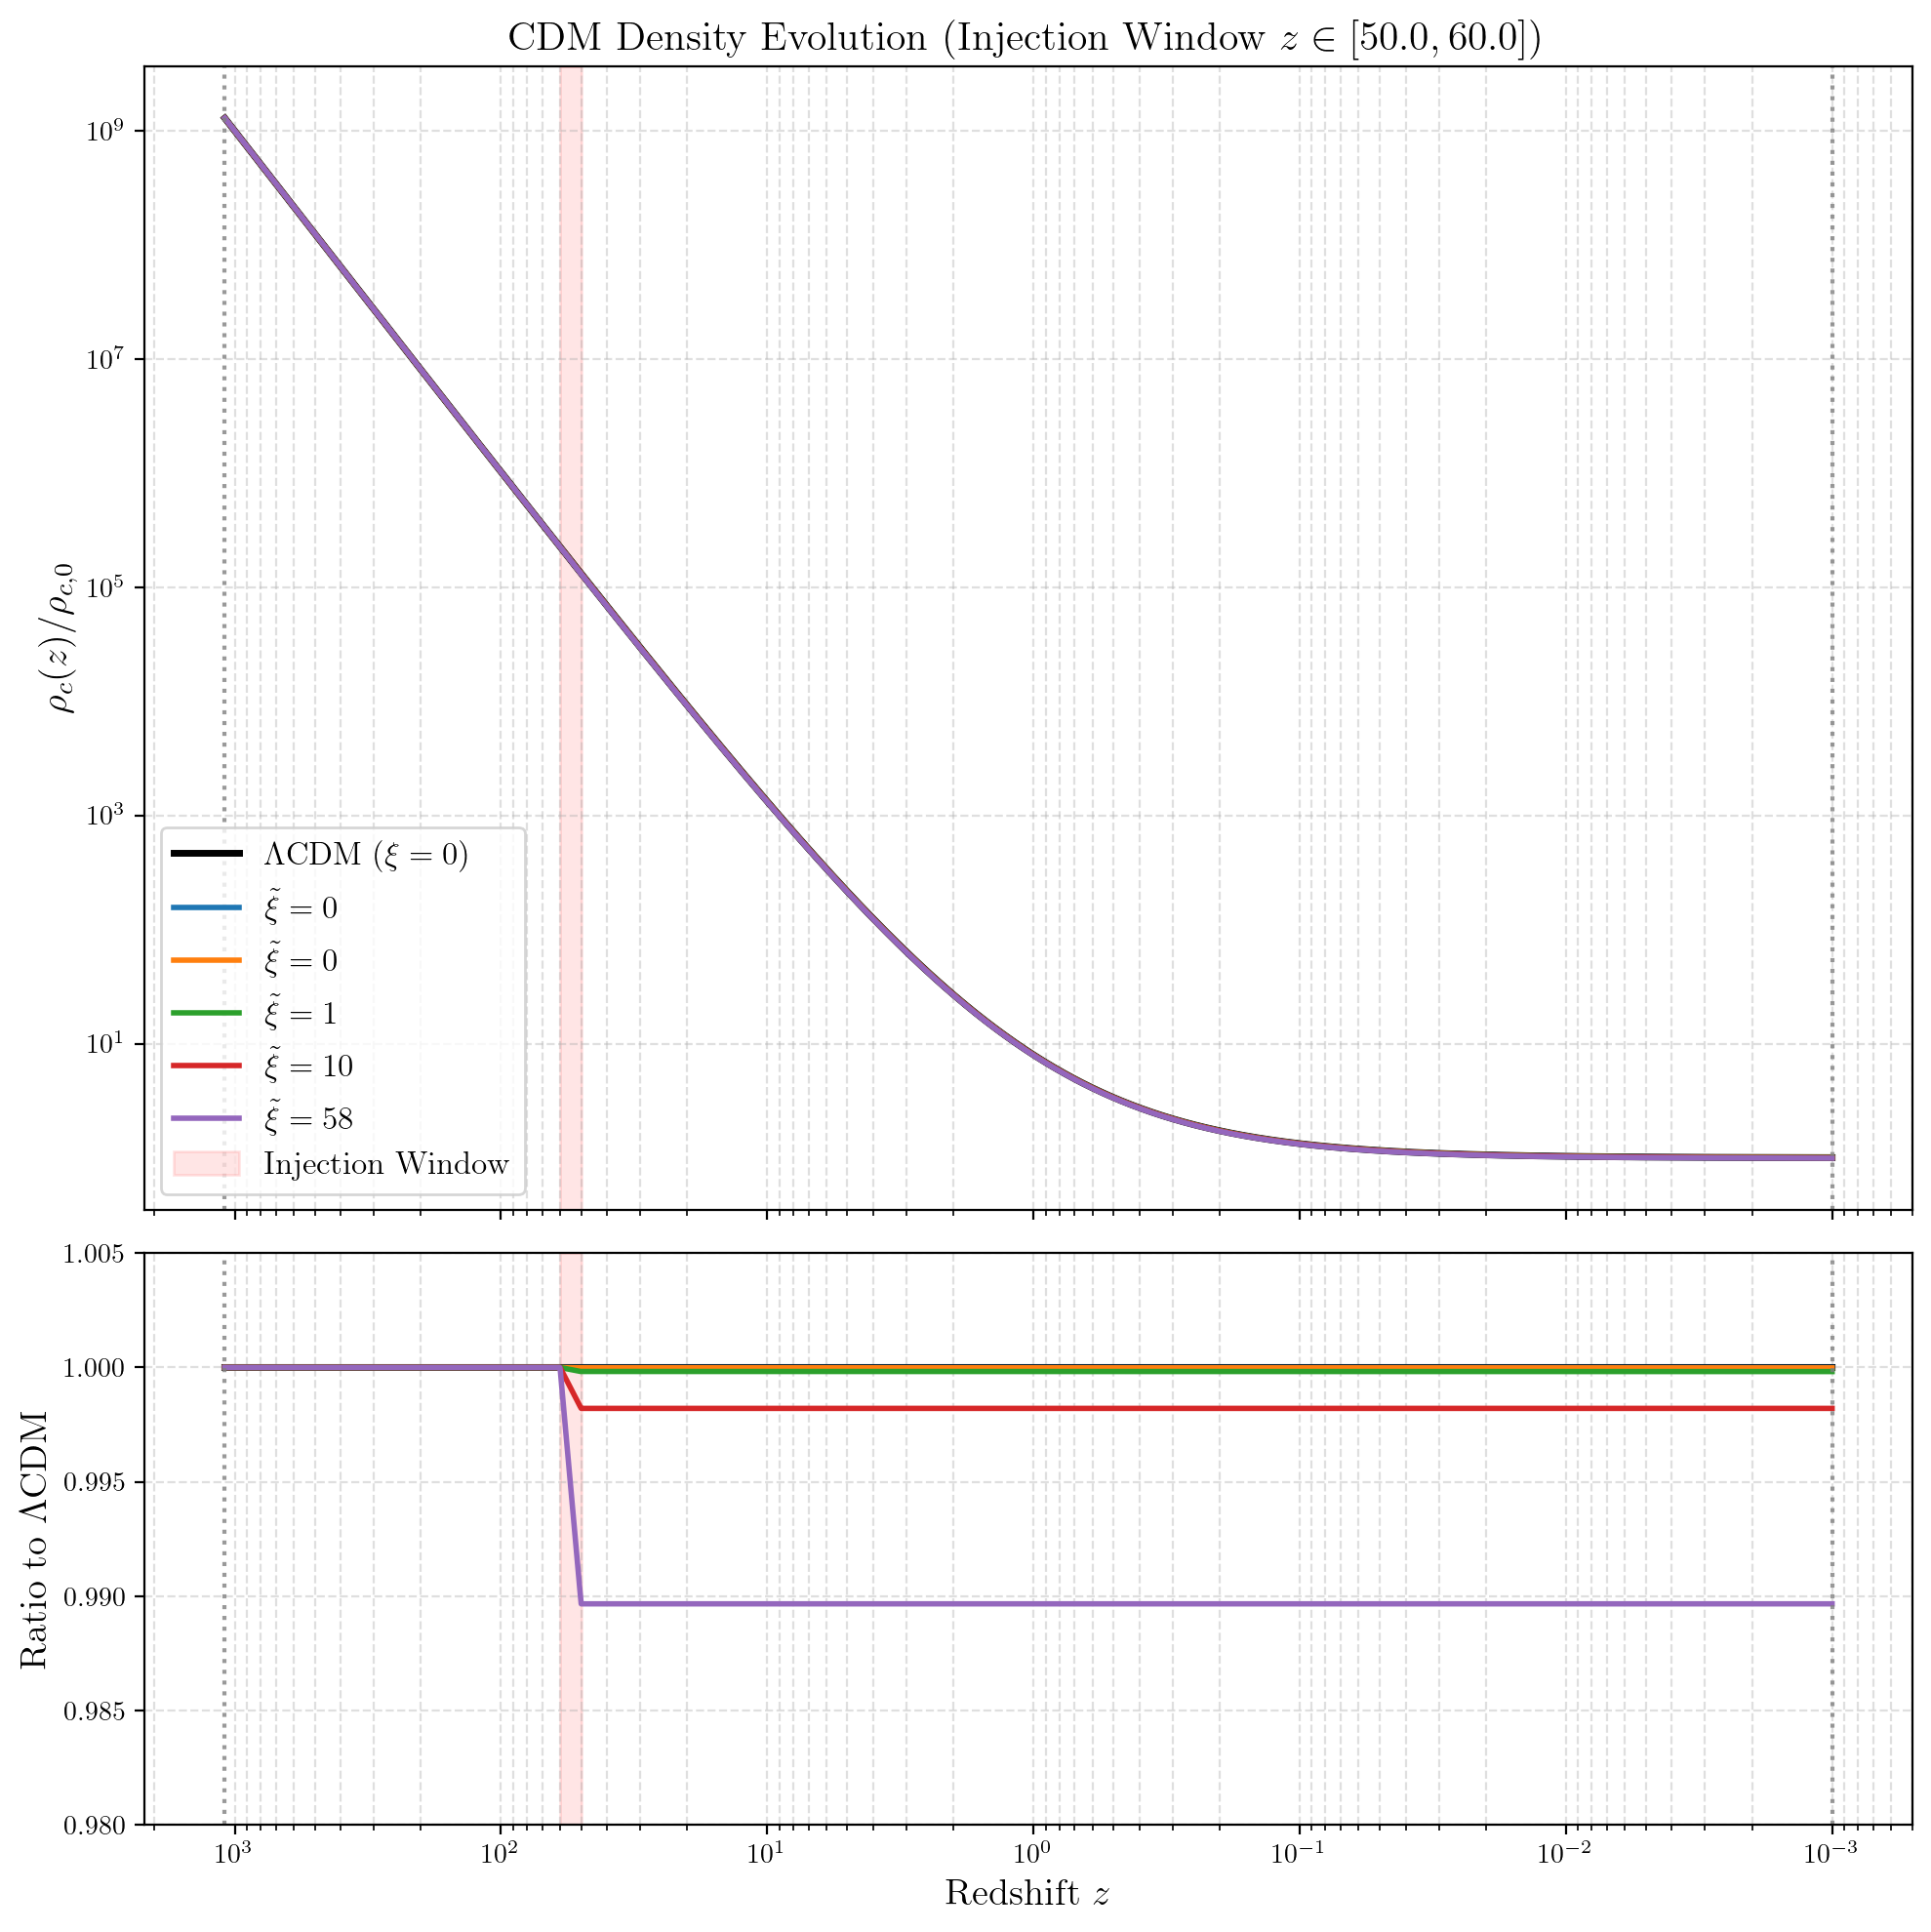

In [3]:
# ==============================================================================
# PARAMETERS FOR THIS SPECIFIC PLOT
# ==============================================================================
z_ini = 1090 # CMB epoch

# Array of redshift values from CMB down to z = 10^-3 (proxy for today on log scale)
z_min_plot = 1e-3
z_vals = np.logspace(np.log10(z_min_plot), np.log10(z_ini), 3000)

# Sweep of xi values for the plot (0.058 is the survival limit ~1% CDM loss, as we can see from these plots)
xi_sweep = [0.0, 1e-5, 1e-4, 1e-3, 1e-2, 0.058] 

# ==============================================================================
# PHYSICS: PIECEWISE DARK MATTER EVOLUTION
# ==============================================================================
def compute_rho_c_step_injection(z_array, xi_val):
    """
    Computes the CDM density evolution given a step-function energy injection.
    The boundary condition anchors the density at high redshift (z > z_start) 
    to the standard Lambda-CDM model to preserve CMB observables.
    """
    rho = np.zeros_like(z_array)
    
    # Phase 1: Pre-injection (z > z_start)
    # Evolving as standard matter (1+z)^3. Identical to Lambda-CDM.
    mask_pre = z_array > z_start
    rho[mask_pre] = (1 + z_array[mask_pre])**3
    
    # Phase 2: During injection (z_end <= z <= z_start)
    # Evolving as (1+z)^(3+xi). We match the boundary at z_start.
    mask_inj = (z_array >= z_end) & (z_array <= z_start)
    rho_at_z_start = (1 + z_start)**3
    rho[mask_inj] = rho_at_z_start * ((1 + z_array[mask_inj]) / (1 + z_start))**(3 + xi_val)
    
    # Phase 3: Post-injection (z < z_end)
    # Evolving as standard matter (1+z)^3 again, but with depleted amplitude.
    mask_post = z_array < z_end
    rho_at_z_end = rho_at_z_start * ((1 + z_end) / (1 + z_start))**(3 + xi_val)
    rho[mask_post] = rho_at_z_end * ((1 + z_array[mask_post]) / (1 + z_end))**3
    
    return rho

# ==============================================================================
# PLOTTING
# ==============================================================================
# We use a 2-panel layout: Absolute Evolution (top) and Ratio (bottom)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True, 
                               gridspec_kw={'height_ratios': [2, 1]})

for xi_val in xi_sweep:
    
    # Calculate piecewise density
    rho_c_z = compute_rho_c_step_injection(z_vals, xi_val)
    
    if xi_val == 0.0:
        # Standard Lambda-CDM Baseline
        ax1.plot(z_vals, rho_c_z, color='black', linewidth=2.5, label=r'$\Lambda$CDM ($\xi=0$)')
        ax2.plot(z_vals, np.ones_like(z_vals), color='black', linewidth=2.5)
    else:
        # Modified CDM (Depleted by Axion Coupling)
        label_str = rf'$\tilde{{\xi}} = {1e3 * xi_val:.0f}$'
        ax1.plot(z_vals, rho_c_z, linewidth=2, label=label_str)
        
        # Calculate the ratio relative to the standard Lambda-CDM
        ratio = rho_c_z / ((1 + z_vals)**3)
        ax2.plot(z_vals, ratio, linewidth=2)

# ==============================================================================
# AESTHETICS AND FORMATTING
# ==============================================================================

# --- Top Panel (Absolute Density) ---
ax1.set_yscale('log')
ax1.set_xscale('log')
ax1.set_ylabel(r'$\rho_c(z) / \rho_{c,0}$', fontsize=14)
ax1.set_title(rf'CDM Density Evolution (Injection Window $z \in [{z_end}, {z_start}]$)', 
              fontsize=15, fontweight='bold')
ax1.grid(True, which='both', linestyle='--', alpha=0.4)

# --- Bottom Panel (Depletion Ratio) ---
ax2.set_ylabel(r'Ratio to $\Lambda$CDM', fontsize=14)
ax2.set_xlabel(r'Redshift $z$', fontsize=14)
ax2.grid(True, which='both', linestyle='--', alpha=0.4)
ax2.set_ylim(0.98, 1.005) # Adjusted slightly to frame the lines better

# --- Highlight the Injection Window ---
for ax in [ax1, ax2]:
    ax.axvspan(z_end, z_start, color='red', alpha=0.1, 
               label='Injection Window' if ax == ax1 else "")

ax1.legend(fontsize=12, loc='lower left')

# --- General X-Axis Settings ---
# Invert X-axis to show time flowing forward from right (CMB) to left (Today)
ax1.invert_xaxis()

# Add vertical reference lines for CMB and Today (approximated at z_min_plot to avoid log(0) errors)
for ax in [ax1, ax2]:
    ax.axvline(x=z_ini, color='gray', linestyle=':', alpha=0.8)
    ax.axvline(x=z_min_plot, color='gray', linestyle=':', alpha=0.8)

plt.tight_layout()
plt.subplots_adjust(hspace=0.05)
plt.show()

# $\rho_\phi(a)$ plot

The continuity equation for the axion energy density $\rho_\phi$ is:

$$\rho'_\phi + 3 \mathcal{H} (p_\phi + \rho_\phi) = Q = \mathcal{H}\xi \rho_c$$

Numerically, it is possible to solve this equation by setting the initial abundance as $\text{Frac} = \frac{\rho_{\phi, ini}}{\rho_{c,0}}$. Analytically, we can substitute the equation of state $p_\phi = w_\phi \rho_\phi$. By also substituting the conformal time derivative $d\tau = \frac{da}{a\mathcal{H}}$, the equation becomes:

$$a \frac{d\rho_\phi}{da} + 3(1+w_\phi) \rho_\phi = \xi \rho_c(a)$$

As for $\rho_c(a)$, we need to divide the integration into three distinct phases. For these phases, we will have a different equation of state $w_\phi$, as well as $\xi$ being zero or non-zero. Using the previous results for $\rho_c(a)$, we obtain:

* **Phase 1 ($a \le a_{\rm start}$):** $$\rho_\phi(a) = \rho_\phi(a_{\rm CMB}) \left(\frac{a}{a_{\rm CMB}}\right)^{-3(1+w_\phi)}$$

* **Phase 2 ($a_{\rm start} < a \le a_{\rm end}$):** The differential equation to solve is:
  $$\frac{d\rho_\phi}{da} + \frac{3(1+w_\phi)}{a} \rho_\phi = \frac{\xi}{a} \rho_c (a_{\rm CMB}) \left(\frac{a_{\rm start}}{a_{\rm CMB}}\right)^{-3} \left(\frac{a}{a_{\rm start}}\right)^{-(3+\xi)}$$
  
  This equation has an exact analytical solution that can be found using the integrating factor method. The solution is:
  $$\rho_\phi(a) = \rho_\phi(a_{\rm start}) \left(\frac{a}{a_{\rm start}}\right)^{-3(1+w_\phi)} + \frac{\xi}{3w_\phi -\xi} \rho_c(a_{\rm start}) \left[ \left(\frac{a}{a_{\rm start}}\right)^{-(3+\xi)} - \left(\frac{a}{a_{\rm start}}\right)^{-3(1+w_\phi)} \right]$$
  
  where the boundary values at $a_{\rm start}$ are:
  $$\rho_\phi(a_{\rm start}) = \rho_\phi (a_{\rm CMB}) \left(\frac{a_{\rm start}}{a_{\rm CMB}}\right)^{-3(1+w_\phi)}$$
  $$\rho_c(a_{\rm start}) = \rho_c (a_{\rm CMB}) \left(\frac{a_{\rm start}}{a_{\rm CMB}}\right)^{-3}$$
  
  Evaluating the solution at $a = a_{\rm end}$, we get:
  $$\rho_\phi (a_{\rm end}) = \rho_\phi(a_{\rm CMB}) \left(\frac{a_{\rm end}}{a_{\rm CMB}}\right)^{-3(1+w_\phi)} + \rho_c(a_{\rm CMB}) \left(\frac{a_{\rm start}}{a_{\rm CMB}}\right)^{-3} \frac{\xi}{3w_\phi -\xi} \left[ \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{-(3+\xi)} - \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{-3(1+w_\phi)} \right]$$

* **Phase 3 ($a > a_{\rm end}$):** $$\rho_\phi(a) = \rho_\phi(a_{\rm end}) \left(\frac{a}{a_{\rm end}}\right)^{-3(1+w_\phi)}$$

***

### Computing the Density Ratio $\rho_\phi / \rho_c$

The relative abundance $\frac{\rho_\phi(a)}{\rho_c(a)}$ can be computed by simply dividing the two resulting arrays, or analytically by expanding it as:

$$\frac{\rho_\phi(a)}{\rho_c(a)} = \frac{\rho_{\phi, ini}}{\rho_{c,0}} \frac{\rho_\phi(a)}{\rho_{\phi, ini}} \frac{\rho_{c,0}}{\rho_c(a)}$$

* If we define our initial fraction with respect to the standard baseline, $\text{Frac} = \frac{\rho_{\phi, ini}}{\rho^{\Lambda\text{CDM}}_{c,0}}$, then:
  $$\frac{\rho_\phi(a)}{\rho_c(a)} = \text{Frac} \times \frac{1}{R(a)} a^3 \frac{\rho_\phi(a)}{\rho_{\phi, ini}}$$

* If we define it with respect to the depleted model, $\text{Frac} = \frac{\rho_{\phi, ini}}{\rho^{\rm Inj-model}_{c,0}}$, then:
  $$\frac{\rho_\phi(a)}{\rho_c(a)} = \text{Frac} \times \frac{R(1)}{R(a)} a^3 \frac{\rho_\phi(a)}{\rho_{\phi, ini}}$$

In this notebook, we set the boundary condition $R(a_{ini}) = R(a_{\rm CMB}) = 1$, meaning that all densities are renormalized with respect to the standard $\rho_{c,0}^{\Lambda\text{CDM}}$ baseline.



***

 ### The analytical formula for the Density Ratio $\rho_\phi / \rho_c$

The analytical formula for the ratio can be easily computed from $\rho_c(a)$ and $\rho_\phi(a)$ by noting that the initial CDM density, $\rho^{\rm inj-mod}_c(a_{ini})$, can be anchored to the standard $\Lambda$ CDM baseline. Indeed, in standard $\Lambda$ CDM, there is no modification to the evolution of $\rho_c$. Therefore, $\rho_c^{\Lambda\text{CDM}}(a_{ini}) = \rho_{c,0}^{\Lambda\text{CDM}} a^{-3}_{ini}$. This relation holds for both the standard model and the injection scenario, provided that the injection occurs well after $a_{ini}$. Consequently, we can set $\rho_{c}^{\rm inj-mod}(a_{ini}) \equiv \rho_{c}^{\Lambda\text{CDM}}(a_{ini})$:

$$\rho^{\rm inj-mod}_c(a_{ini}) = \rho_{c,0}^{\Lambda\text{CDM}} a^{-3}_{ini}$$

The explicit formula for the density ratio depends on the specific interval being considered. 

Moreover, a significant complication arises from the axion equation of state, $w_\phi$. The analytical computation is inherently an approximation because $w_\phi$ is not a simple constant, nor does it transition instantaneously from $w_\phi = -1$ to $w_\phi = 0$. If we assume a piecewise approximation where no intermediate kinetic phase exists, we must define an exact scale factor for this sudden phase transition. 

A first, conservative approximation is to force the transition $w_\phi = -1 \rightarrow 0$ at $a_{\rm end}$, i.e., immediately at the end of the energy injection. A second approach is to assume the transition occurs when the axion naturally begins to oscillate, meaning when $3H(a_{\rm osc}) \simeq m_a$. Assuming this happens during the matter-dominated era, where $H(a) \simeq H_0 \sqrt{\Omega_m a^{-3}}$, the scale factor $a_{\rm osc}$ can be analytically computed as:

$$3H_0 \sqrt{\Omega_m a_{\rm osc}^{-3}} = m_a \implies a_{\rm osc} = \left( \frac{3 H_0 \sqrt{\Omega_m}}{m_a} \right)^{2/3}$$

which corresponds to a thawing redshift of:

$$z_{\rm osc} = \left( \frac{m_a}{3 H_0 \sqrt{\Omega_m}} \right)^{2/3} - 1$$

However, both of these approximations fail to capture critical aspects of the actual dynamics. Primarily, the phase transition is not instantaneous: the violent energy injection triggers a transient kinetic phase (*kination*, where $w_\phi \approx 1$), which leads to rapid energy dissipation. The severity and duration of this intermediate phase strongly depend on the amount of injected energy, governed by the parameter $\xi$.


In the following, we can see the two plots (dotted green and dotted orange) and how they approximate the exact numerical result (in blue).


In [4]:
# ==============================================================================
# Computing the oscillation point: H(a_{osc})\simeq m_a
# ==============================================================================

def compute_z_osc(logm_val, H0_val, Om_val):
    """
    Computes the analytical oscillation redshift z_osc for an axion of mass logm,
    given the background cosmology.
    """
    m_a_eV = 10**logm_val
    km_s_Mpc_to_eV = 2.13313e-35
    H0_eV_local = H0_val * km_s_Mpc_to_eV
    arg = m_a_eV / (3.0 * H0_eV_local * np.sqrt(Om_val))
    return (arg)**(2.0/3.0) - 1.0

# Calculate the analytical thawing redshift using global parameters
z_osc_exact = compute_z_osc(logm, H0_km_s_Mpc, Om_M)
a_osc = 1.0 / (1.0 + z_osc_exact)

print(f"--- Analytical Check ---")
print(f"Analytical thawing redshift: z_osc = {z_osc_exact:.2f}\n")

--- Analytical Check ---
Analytical thawing redshift: z_osc = 24.92



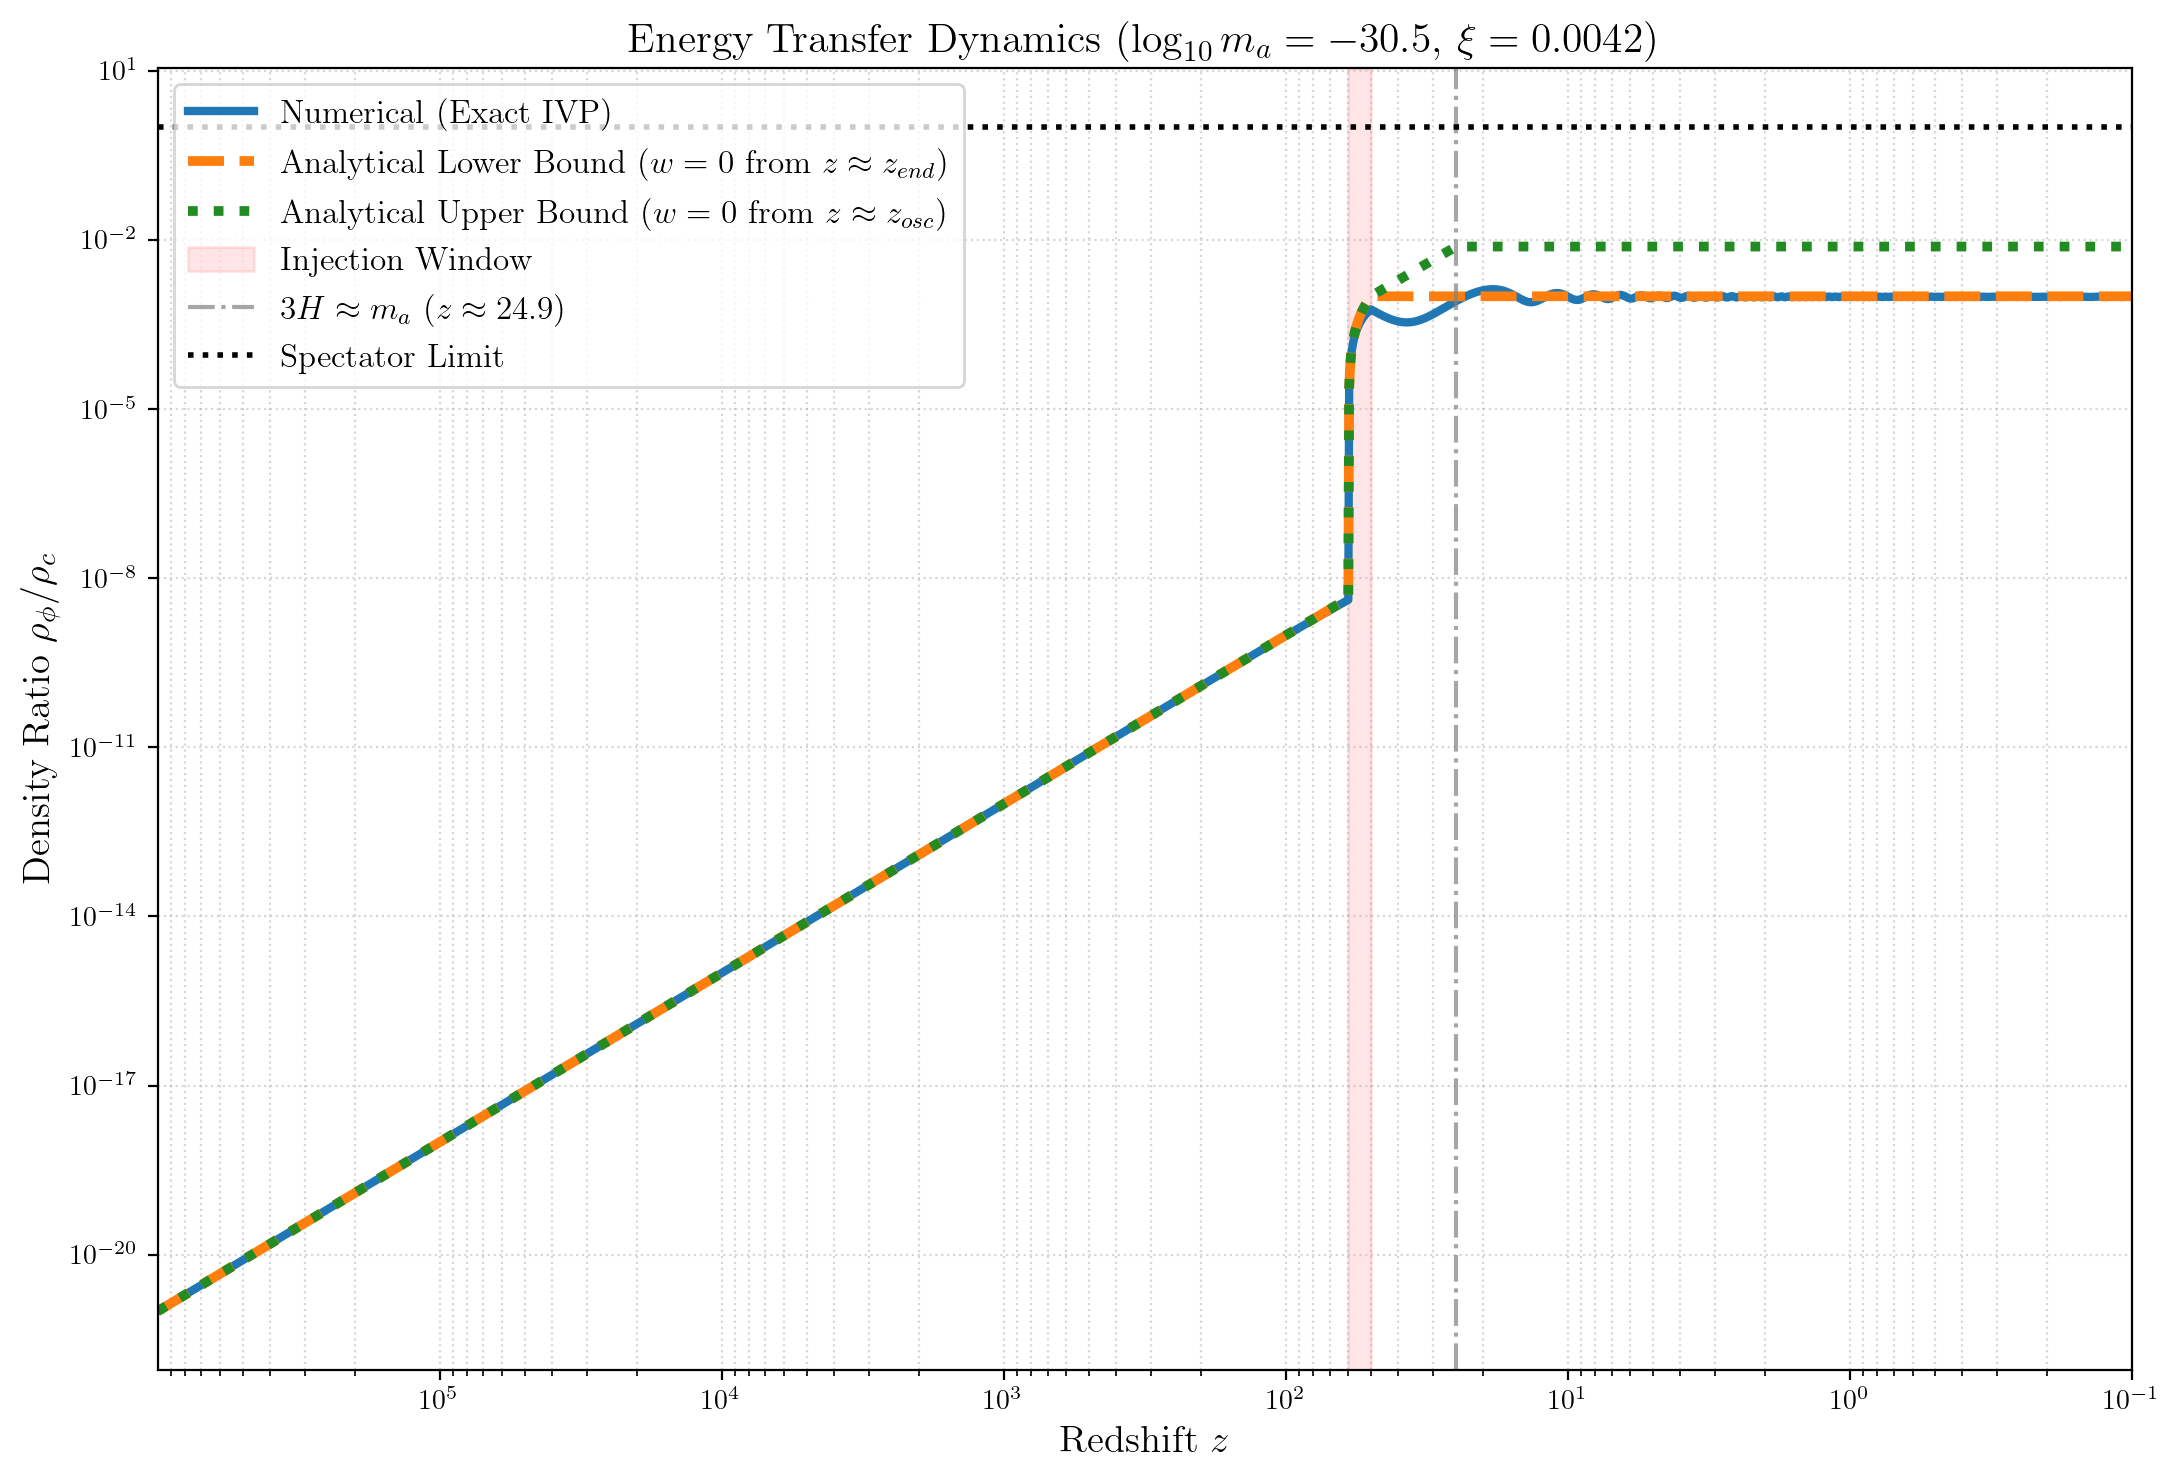

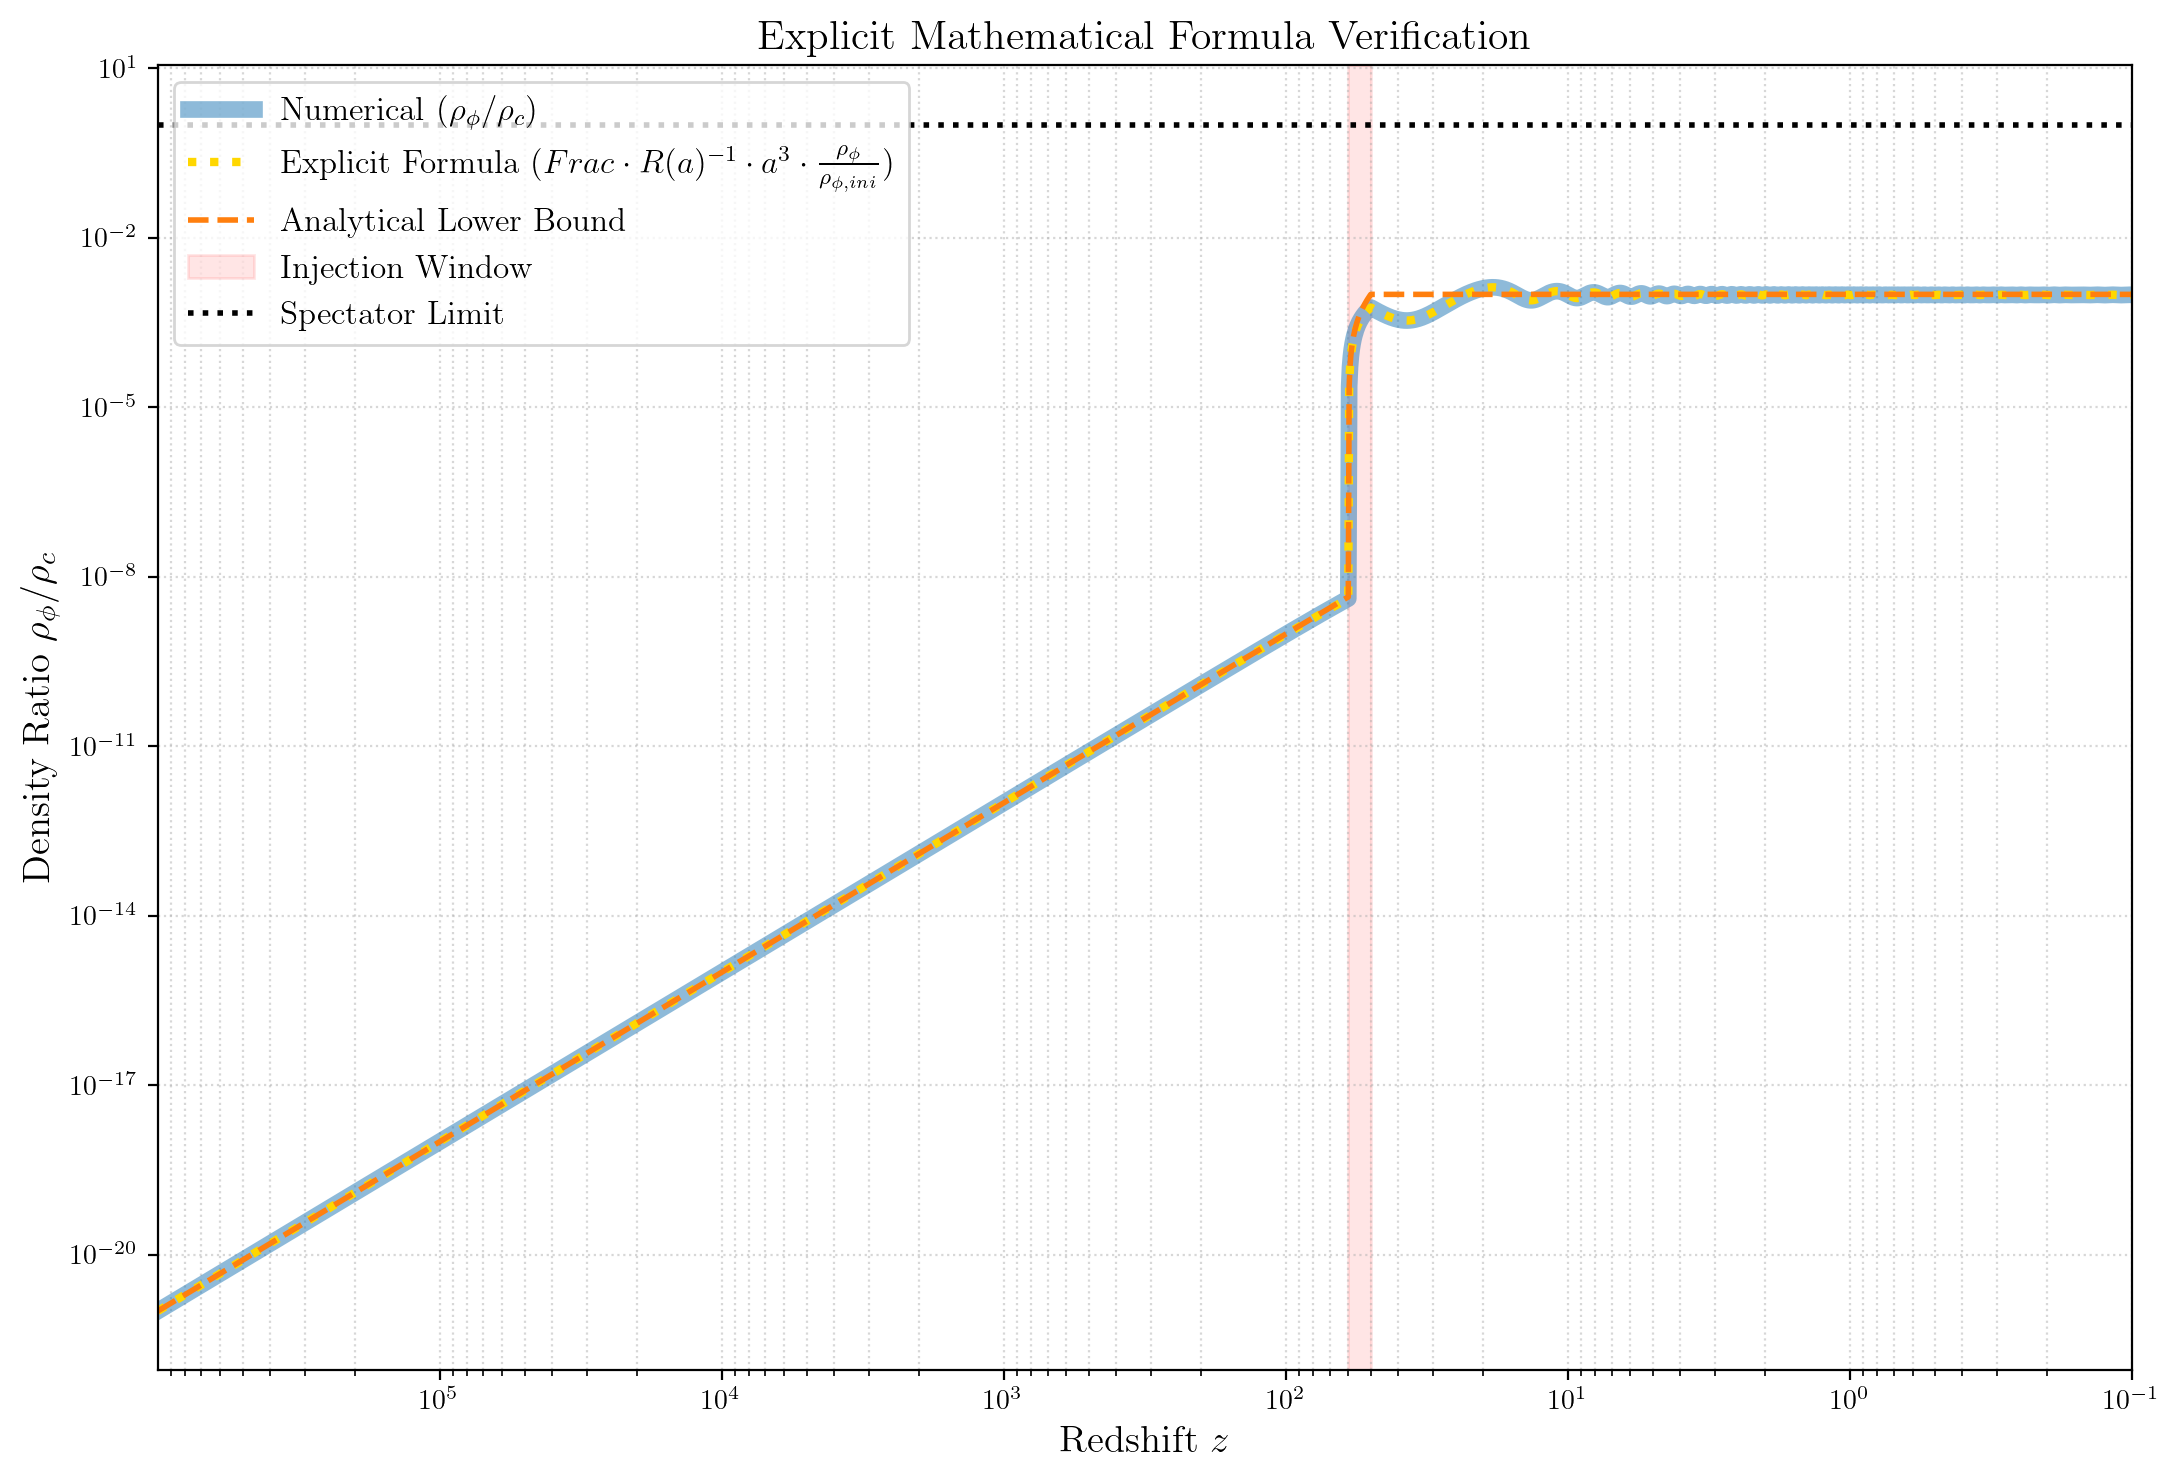

In [5]:
# ==============================================================================
# EXACT DENSITY RATIO CALCULATION & PLOTTING
# ==============================================================================

# ==============================================================================
# 1. NUMERICAL SOLUTION (EXACT IVP)
# ==============================================================================
phi = solve_ivp(local.EoM_phi, [a[0], 1], [bphi0_ini, bphi1_ini], 
                t_eval=a, args=[logm, tf, n, xi, eps, z_start, z_end, bphi0_ini], 
                atol=atol, rtol=rtol, method="RK45")

x0 = phi['y'][0]  
x1 = phi['y'][1]  

# Axion numerical energy densities
H_a = local.H0Mpc * np.array([local.Ea(a_val) for a_val in a])
K_local = 0.5 * (a * H_a * x1)**2
V_local = np.array([local.V_phi(val, logm, tf, n, deriv=0) for val in x0])
rho_phi_local = K_local + V_local

# Normalization 
V_ini_local = local.V_phi(1.0, logm, tf, n, deriv=0)
rho_phi_over_rho_c0 = rho_phi_local * (frac / V_ini_local)

# Exact CDM density computation R(a)
R_a = np.ones_like(a)
mask_phase1 = a < a_start
mask_phase2 = (a >= a_start) & (a <= a_end)
mask_phase3 = a > a_end

R_a[mask_phase1] = 1.0
R_a[mask_phase2] = (a[mask_phase2] / a_start)**(-xi)
R_a[mask_phase3] = (a_end / a_start)**(-xi)

rho_c_over_rho_c0 = (a**-3) * R_a

# Final numerical ratio
ratio_num = rho_phi_over_rho_c0 / rho_c_over_rho_c0


# ==============================================================================
# 2. ANALYTICAL MODELS (a_end vs a_osc Transitions)
# ==============================================================================
# Note: z_osc_exact and a_osc are inherited from the previous cell.

w_phi_early = -1.0  
w_phi_late  = 0.0   

# Boundary conditions at a_start
rho_c_start = (a_start**-3) * 1.0
rho_phi_start = rho_phi_ini * (a_start / a_ini)**(-3*(1 + w_phi_early))

# Exact analytical kick accumulated at a_end
kick_end = (xi / (3*w_phi_early - xi)) * rho_c_start * \
           ( (a_end/a_start)**-(3+xi) - (a_end/a_start)**(-3*(1+w_phi_early)) )
rho_phi_end = rho_phi_start * (a_end / a_start)**(-3*(1 + w_phi_early)) + kick_end

rho_phi_ana_end = np.zeros_like(a)
rho_phi_ana_osc = np.zeros_like(a)

for i, a_val in enumerate(a):
    
    if a_val < a_start:
        rho_phi_ana_end[i] = rho_phi_ini * (a_val / a_ini)**(-3*(1 + w_phi_early))
        rho_phi_ana_osc[i] = rho_phi_ini * (a_val / a_ini)**(-3*(1 + w_phi_early))
        
    elif a_val <= a_end:
        kick = (xi / (3*w_phi_early - xi)) * rho_c_start * \
               ( (a_val/a_start)**-(3+xi) - (a_val/a_start)**(-3*(1+w_phi_early)) )
        val = rho_phi_start * (a_val / a_start)**(-3*(1 + w_phi_early)) + kick
        rho_phi_ana_end[i] = val
        rho_phi_ana_osc[i] = val
        
    else:
        # MODEL A: Forced switch to w=0 at a_end
        rho_phi_ana_end[i] = rho_phi_end * (a_val / a_end)**(-3*(1 + w_phi_late))
        
        # MODEL B: Delayed switch to w=0 at a_osc
        if a_val <= a_osc:
            rho_phi_ana_osc[i] = rho_phi_end 
        else:
            rho_phi_ana_osc[i] = rho_phi_end * (a_val / a_osc)**(-3*(1 + w_phi_late))

ratio_ana_end = rho_phi_ana_end / rho_c_over_rho_c0
ratio_ana_osc = rho_phi_ana_osc / rho_c_over_rho_c0

# ==============================================================================
# PLOT 1: DYNAMICS COMPARISON
# ==============================================================================
plt.figure(figsize=(11, 7.5))

plt.plot(z, ratio_num, color='C0', linewidth=3, 
         label='Numerical (Exact IVP)')
plt.plot(z, ratio_ana_end, color='C1', linewidth=3.5, linestyle='--',
         label=r'Analytical Lower Bound ($w=0$ from $z \approx z_{end}$)')
plt.plot(z, ratio_ana_osc, color='forestgreen', linewidth=3.5, linestyle=':',
         label=r'Analytical Upper Bound ($w=0$ from $z \approx z_{osc}$)')

plt.axvspan(z_start, z_end, color='red', alpha=0.1, label='Injection Window')
plt.axvline(z_osc_exact, color='gray', linestyle='-.', alpha=0.7, 
            label=rf'$3H \approx m_a$ ($z \approx {z_osc_exact:.1f}$)')
plt.axhline(1.0, color='black', linestyle=':', linewidth=2, label='Spectator Limit')

plt.xscale('log')
plt.yscale('log')
z_min_plot = 1e-1 if min(z) <= 0 else min(z)
plt.xlim(max(z), z_min_plot) 

plt.xlabel(r'Redshift $z$', fontsize=14)
plt.ylabel(r'Density Ratio $\rho_\phi / \rho_c$', fontsize=14)
plt.title(rf'Energy Transfer Dynamics ($\log_{{10}}m_a={logm}$, $\xi={xi}$)', fontsize=15, fontweight='bold')
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, which='both', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# PLOT 2: EXPLICIT FORMULA VERIFICATION
# ==============================================================================
axion_norm_evol = rho_phi_local / V_ini_local
ratio_explicit_formula = frac * (1.0 / R_a) * (a**3) * axion_norm_evol 

plt.figure(figsize=(11, 7.5))

plt.plot(z, ratio_num, color='C0', linewidth=6, alpha=0.5,
         label=r'Numerical ($\rho_\phi / \rho_c$)')
plt.plot(z, ratio_explicit_formula, color='gold', linestyle=':', linewidth=3, 
         label=r'Explicit Formula ($Frac \cdot R(a)^{-1} \cdot a^3 \cdot \frac{\rho_\phi}{\rho_{\phi,ini}}$)')
plt.plot(z, ratio_ana_end, color='C1', linewidth=2, linestyle='--',
         label=r'Analytical Lower Bound')

plt.axvspan(z_start, z_end, color='red', alpha=0.1, label='Injection Window')
plt.axhline(1.0, color='black', linestyle=':', linewidth=2, label='Spectator Limit')

plt.xscale('log')
plt.yscale('log')
plt.xlim(max(z), z_min_plot) 

plt.xlabel(r'Redshift $z$', fontsize=14)
plt.ylabel(r'Density Ratio $\rho_\phi / \rho_c$', fontsize=14)
plt.title('Explicit Mathematical Formula Verification', fontsize=15, fontweight='bold')
plt.legend(fontsize=12, loc='upper left')
plt.grid(True, which='both', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

***

# The Exclusion Plot Boundaries

## 1) Maximum injection parameter $\xi_{max}$

In determining the allowed parameter space, the dynamical breaking of the potential ($\xi_{crit}$) is not our only upper bound. We must also ensure that the Cold Dark Matter (CDM) is not excessively depleted by the energy injection, as observational constraints on the total matter density $\Omega_M$ are highly stringent. 

To remain consistent with these bounds, we conservatively require the total CDM depletion to be less than 1% today. This implies:

$$1 - R(a_0) = 1 - \frac{\rho_c^{\rm inj-mod}(a_0)}{\rho_c^{\Lambda\text{CDM}}(a_0)} < 10^{-2} \implies R(a_0) > 0.99$$

Using the analytical evolution derived for the post-injection phase, we require:

$$\left(\frac{1+z_{\rm start}}{1+z_{\rm end}}\right)^{-\xi} > 0.99$$

Solving for $\xi$, we obtain a background upper bound that is entirely independent of the axion mass, dictated solely by the width of the injection window:

$$\xi < \frac{-\ln(0.99)}{\ln\left(\frac{1+z_{\rm start}}{1+z_{\rm end}}\right)}$$

For our benchmark injection window ($z_{\rm start} = 60$ and $z_{\rm end} = 50$), this yields a strict background limit of:

$$\xi \lesssim 0.0561$$

Therefore, the absolute upper bound on the injection parameter is defined by the most restrictive condition between the background CDM depletion limit ($\xi_c^{\max}$) and the non-linear dynamical breaking limit of the axion potential ($\xi_{crit}(m_a)$):

$$\xi_{\max} = \min \left( \xi_{c}^{\max}, \, \xi_{crit}(m_a) \right)$$



In [6]:
# ==============================================================================
# MAXIMUM INJECTION PARAMETER COMPUTATION
# ==============================================================================

def compute_xi_max(z_start_val, z_end_val, logm_val=None, xi_crit_dyn=None):
    """
    Computes the maximum allowed injection parameter xi_max by comparing 
    the 1% CDM depletion limit with the dynamical potential breaking limit.
    """
    # 1. Background CDM Constraint (max 1% depletion)
    ratio_z = (1.0 + z_start_val) / (1.0 + z_end_val)
    xi_cdm_limit = -np.log(0.99) / np.log(ratio_z)
    
    print(f"--- Upper Bound Analysis ---")
    print(f"Injection Window: z in [{z_end_val}, {z_start_val}]")
    print(f"1) CDM Depletion Limit (1%): xi_c_max = {xi_cdm_limit:.5f}")
    
    # 2. Dynamical Constraint (if provided)
    # Dictionary of your known dynamical breaking points
    known_xi_crits = {
        -30.6: 0.0227386,
        -30.5: 0.0163025,
        -30.4: 0.0118965
    }
    
    # Check if we should look up the value or use a manually provided one
    if xi_crit_dyn is None and logm_val in known_xi_crits:
        xi_crit_dyn = known_xi_crits[logm_val]
        
    if xi_crit_dyn is not None:
        print(f"2) Dynamical Breaking Limit: xi_crit  = {xi_crit_dyn:.5f} (for logm = {logm_val})")
        
        # The true upper bound is the minimum of the two
        xi_final_max = min(xi_cdm_limit, xi_crit_dyn)
        
        # Identify which physical constraint is acting as the bottleneck
        bottleneck = "Dynamical Breaking" if xi_crit_dyn < xi_cdm_limit else "CDM Depletion"
        print(f"--> Final xi_max: {xi_final_max:.5f} (Constrained by: {bottleneck})")
        
        return xi_final_max
    else:
        print(f"--> Final xi_max: {xi_cdm_limit:.5f} (No dynamical limit provided)")
        return xi_cdm_limit

# Esempio di utilizzo nel tuo codice:
# (Usa i parametri presi dalla tua Global Cell)
true_xi_max = compute_xi_max(z_start_val=60.0, z_end_val=50.0, logm_val=-30.5)

--- Upper Bound Analysis ---
Injection Window: z in [50.0, 60.0]
1) CDM Depletion Limit (1%): xi_c_max = 0.05613
2) Dynamical Breaking Limit: xi_crit  = 0.01630 (for logm = -30.5)
--> Final xi_max: 0.01630 (Constrained by: Dynamical Breaking)


***

### 2) ALP as a Spectator Field

A second fundamental constraint arises from the requirement that the Axion-Like Particle (ALP) must remain a spectator field throughout the cosmic evolution. This condition is enforced by demanding that its energy density never exceeds $1\%$ of the local Cold Dark Matter (CDM) density:

$$\max \left[ \frac{\rho_\phi(a)}{\rho_c(a)} \right] \le 10^{-2}$$

Using the identity $\rho^{\rm inj-mod}_c(a_{ini}) \equiv \rho_{c,0}^{\Lambda\text{CDM}} a^{-3}_{ini}$ discussed previously, the density ratio scales linearly with the initial energy fraction $\text{Frac} = \frac{\rho_{\phi, ini}}{ \rho_{c, 0}^{\Lambda\text{CDM}}}$. Therefore, finding the maximum of the ratio directly yields the upper bound for the allowed $\text{Frac}$ at a given $\xi$.

As analyzed before, the true maximum of this ratio depends on the non-linear kinetic dissipation. However, analytically, the peak can be approximated by forcing the equation of state transition ($w_\phi = -1 \rightarrow 0$) at two extreme scale factors: $a_{\rm end}$ or $a_{\rm osc}$. 

**Case 1: Transition at $a_{\rm end}$ (Lower Bound Approximation)**
Assuming the axion begins to dilute as matter immediately after the energy injection ceases, the maximum ratio is reached at $a_{\rm end}$. By integrating the equations of motion with $w_\phi = -1$, the analytical peak is:

$$\left[ \frac{\rho_\phi}{\rho_c} \right]_{a_{\rm end}} = \text{Frac} \cdot a_{\rm end}^3 \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{\xi} + \frac{\xi}{3+\xi} \left[ \left(\frac{a_{\rm end}}{a_{\rm start}}\right)^{3+\xi} - 1 \right]$$

**Case 2: Transition at $a_{\rm osc}$ (Upper Bound Approximation)**
Assuming instead that the axion energy remains perfectly frozen in the potential well ($w_\phi = -1$) until the natural thawing redshift $a_{\rm osc}$, the density ratio is further amplified during the "free-ride" expansion from $a_{\rm end}$ to $a_{\rm osc}$. Since CDM dilutes as $a^{-3}$ while the axion remains constant, the maximum ratio is:

$$\left[ \frac{\rho_\phi}{\rho_c} \right]_{a_{\rm osc}} = \left[ \frac{\rho_\phi}{\rho_c} \right]_{a_{\rm end}} \times \left( \frac{a_{\rm osc}}{a_{\rm end}} \right)^3$$

Below, we compute and plot the parameter space $(\text{Frac}, \xi)$ exclusion limits derived from both approximations. As we will demonstrate, both fail to capture the transient kinetic phase (kination) and the anharmonic delay, necessitating a fully numerical solution.

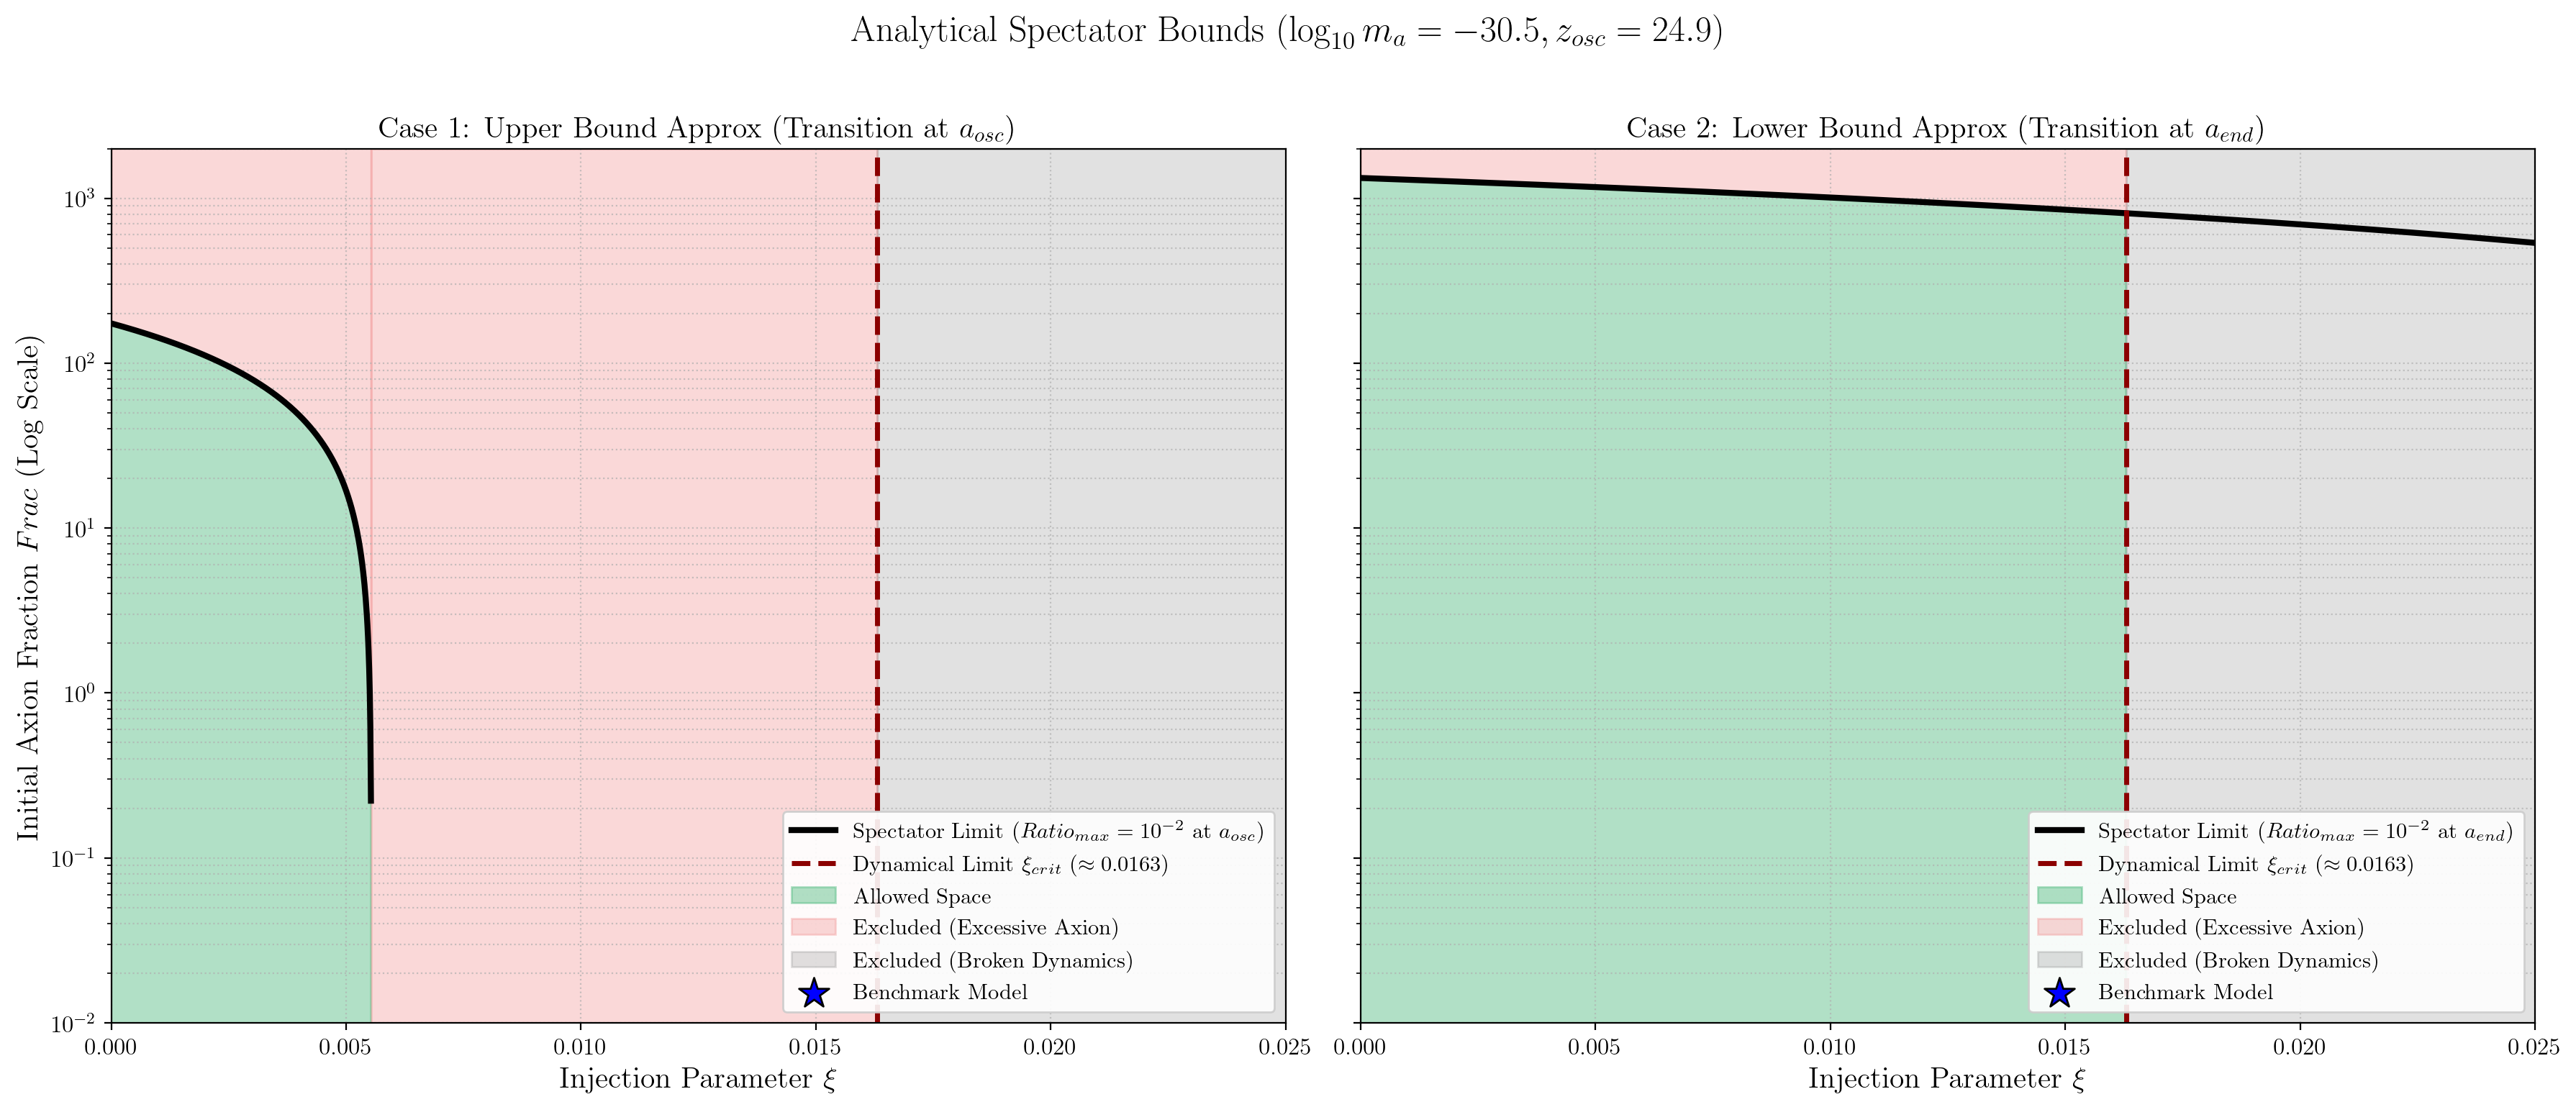

In [7]:
# ==============================================================================
# ANALYTICAL EXCLUSION PLOTS: CASE 1 (a_osc) & CASE 2 (a_end)
# ==============================================================================


# --- 1. Local Variables & Setup ---
# Derived from global parameters (z_start, z_end, z_osc_exact, xi_crit)
y = (1.0 + z_start) / (1.0 + z_end) 
a_start = 1.0 / (1.0 + z_start)
a_end = 1.0 / (1.0 + z_end)
a_osc = 1.0 / (1.0 + z_osc_exact)

xi_vals = np.linspace(0.0, 0.025, 2000)
benchmark_xi = 0.01
benchmark_frac = 1e-3

# ==============================================================================
# 2. MATH: CASE 1 (Delayed Transition at a_osc)
# ==============================================================================
kick_end_1 = (xi_vals / (3.0 + xi_vals)) * (y**(3.0 + xi_vals) - 1.0)
amplification = (a_osc / a_end)**3
kick_osc = amplification * kick_end_1

valid_mask_1 = (0.01 - kick_osc) > 0
Frac_max_1 = np.full_like(xi_vals, np.nan)
Frac_max_1[valid_mask_1] = (0.01 - kick_osc[valid_mask_1]) / (a_osc**3 * y**xi_vals[valid_mask_1])
xi_cutoff_1 = xi_vals[valid_mask_1][-1]

# ==============================================================================
# 3. MATH: CASE 2 (Immediate Transition at a_end)
# ==============================================================================
kick_end_2 = (xi_vals / (3.0 + xi_vals)) * (y**(3.0 + xi_vals) - 1.0)

valid_mask_2 = (0.01 - kick_end_2) > 0
Frac_max_2 = np.full_like(xi_vals, np.nan)
Frac_max_2[valid_mask_2] = (0.01 - kick_end_2[valid_mask_2]) / (a_end**3 * y**xi_vals[valid_mask_2])
# Per il caso 2, solitamente il cutoff non si raggiunge prima di xi_crit, 
# ma lo calcoliamo per sicurezza del plotting
xi_cutoff_2 = xi_vals[valid_mask_2][-1] if len(xi_vals[valid_mask_2]) > 0 else 0

# ==============================================================================
# 4. PLOTTING (1 Row, 2 Columns)
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7.5), sharey=True)

# ------------------------------------------------------------------------------
# PANEL 1: Case 1 (Transition at a_osc)
# ------------------------------------------------------------------------------
ax1.plot(xi_vals, Frac_max_1, color='black', linewidth=3, 
         label=r'Spectator Limit ($Ratio_{max} = 10^{-2}$ at $a_{osc}$)')
ax1.axvline(xi_crit, color='darkred', linestyle='--', linewidth=2.5, 
            label=rf'Dynamical Limit $\xi_{{crit}}$ ($\approx {xi_crit:.4f}$)')

ax1.fill_between(xi_vals, 1e-10, Frac_max_1, where=valid_mask_1, 
                 color='mediumseagreen', alpha=0.4, label='Allowed Space')
ax1.fill_between(xi_vals, Frac_max_1, 1e5, where=valid_mask_1, 
                 color='lightcoral', alpha=0.3, label='Excluded (Excessive Axion)')
ax1.axvspan(xi_cutoff_1, xi_crit, color='lightcoral', alpha=0.3)
ax1.axvspan(xi_crit, max(xi_vals), color='dimgray', alpha=0.2, 
            label=r'Excluded (Broken Dynamics)')

ax1.scatter([benchmark_xi], [benchmark_frac], color='blue', s=250, marker='*', zorder=5, 
            edgecolor='black', label=r'Benchmark Model')

ax1.set_title(r'Case 1: Upper Bound Approx (Transition at $a_{osc}$)', fontsize=15, fontweight='bold')
ax1.set_ylabel(r'Initial Axion Fraction $Frac$ (Log Scale)', fontsize=15)

# ------------------------------------------------------------------------------
# PANEL 2: Case 2 (Transition at a_end)
# ------------------------------------------------------------------------------
ax2.plot(xi_vals, Frac_max_2, color='black', linewidth=3, 
         label=r'Spectator Limit ($Ratio_{max} = 10^{-2}$ at $a_{end}$)')
ax2.axvline(xi_crit, color='darkred', linestyle='--', linewidth=2.5, 
            label=rf'Dynamical Limit $\xi_{{crit}}$ ($\approx {xi_crit:.4f}$)')

ax2.fill_between(xi_vals, 1e-10, Frac_max_2, where=(xi_vals <= xi_crit), 
                 color='mediumseagreen', alpha=0.4, label='Allowed Space')
ax2.fill_between(xi_vals, Frac_max_2, 1e6, where=(xi_vals <= xi_crit), 
                 color='lightcoral', alpha=0.3, label='Excluded (Excessive Axion)')
ax2.axvspan(xi_crit, max(xi_vals), color='dimgray', alpha=0.2, 
            label=r'Excluded (Broken Dynamics)')

ax2.scatter([benchmark_xi], [benchmark_frac], color='blue', s=250, marker='*', zorder=5, 
            edgecolor='black', label=r'Benchmark Model')

ax2.set_title(r'Case 2: Lower Bound Approx (Transition at $a_{end}$)', fontsize=15, fontweight='bold')

# ------------------------------------------------------------------------------
# GLOBAL AESTHETICS (Applied to both axes)
# ------------------------------------------------------------------------------
for ax in [ax1, ax2]:
    ax.set_xlim(0, 0.025)
    ax.set_yscale('log')
    ax.set_xlabel(r'Injection Parameter $\xi$', fontsize=15)
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.grid(True, which='both', linestyle=':', alpha=0.7)
    
    # Clean up duplicate legend entries
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), fontsize=11, loc='lower right', framealpha=0.9)

# Adjust y-limits globally since they share the Y axis
ax1.set_ylim(1e-2, 2e3) 

fig.suptitle(rf'Analytical Spectator Bounds ($\log_{{10}} m_a = {logm}, z_{{osc}} = {z_osc_exact:.1f}$)', 
             fontsize=18, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

***

### The Numerical Exclusion Plot

The fundamental issue with the two analytical solutions ($a_{\rm osc}$ and $a_{\rm end}$) is that they assume an instantaneous transition of the equation of state from $w_\phi = -1$ to $w_\phi = 0$. In reality, this transition cannot be treated as a sudden step. Following a strong energy injection, the field is driven into a phase where $w_\phi$ varies continuously. In extreme cases, it can even reach $w_\phi \approx 1$, a regime completely dominated by the newly acquired kinetic energy that the field has not yet had time to dissipate. This violent transient phase is known as **kination**.

Furthermore, the dynamics are characterized by a **"free-ride"** phenomenon: between $a_{\rm end}$ and $a_{\rm osc}$, the axion is heavily damped by Hubble friction and remains effectively frozen in the potential. If we strictly apply the $a_{\rm end}$ transition approximation, this advantageous free-ride phase is entirely ignored.

Consequently, for certain low values of $\xi$, the best approximation for the density ratio $\rho_\phi/\rho_c$ is provided by the analytical formula transitioning at $a_{\rm end}$. In other regimes, the $a_{\rm osc}$ formula becomes more accurate. Relying exclusively on the $a_{\rm end}$ approach to draw the exclusion plot would yield dangerously permissive bounds, whereas strictly using the $a_{\rm osc}$ formula would produce excessively restrictive limits.

The most robust and physically sound solution is to transition to a fully numerical approach, as demonstrated by the tests below. 

For the exact numerical procedure, we rely on the fact that the background equations dictate a linear scaling between the final density ratio and the initial fractional abundance $\text{Frac}$:

$$\frac{\rho_\phi}{\rho_c} = \text{Frac} \times \mathcal{T}(\xi, a) $$

By factoring out $\text{Frac}$, we can define the scale-independent transfer function of the energy injection evaluated today ($a = 1$):

$$\mathcal{T}(\xi) = \left[ \frac{1}{R(a)} a^3 \frac{\rho_\phi(a)}{\rho_{\phi, ini}} \right]_{a = 1}$$

Since the analytical formula alone cannot capture the non-linear kination and anharmonic delays, we use the differential solver strictly to extract this exact numerical transfer function $\mathcal{T}(\xi)$. 

Once the exact transfer function is computed, the maximum allowed initial fraction is trivially found by direct inversion of the spectator limit ($\text{Frac} \times \mathcal{T}(\xi) \le 10^{-2}$):

$$\text{Frac}_{\max}(\xi) = \frac{10^{-2}}{\mathcal{T}(\xi)}$$

In [15]:
# ==============================================================================
# EXACT NUMERICAL TEST (Using strictly GLOBAL parameters)
# ==============================================================================
# No local redefinitions. We inherit logm, frac, z_start, z_end, y, a_end, a_osc, 
# and xi_max directly from the previous cells.

# Array of xi values to test (20 points from 0 up to 95% of the dynamical limit)
xi_test_vals = np.linspace(0.0, true_xi_max * 0.999, 20)

# Baseline axion potential normalizer (calculated once outside the loop)
V_ini_local = local.V_phi(1.0, logm, tf, n, deriv=0)

# ==============================================================================
# EXECUTE SCANS AND PRINT COMPARISON TABLE
# ==============================================================================
print(f"{'xi':<8} | {'Num Plateau':<15} | {'Analytical (a_end)':<20} | {'Analytical (a_osc)':<20}")
print("-" * 75)

for xi_val in xi_test_vals:
    
    # ------------------------------------------------------------------
    # A. ANALYTICAL MODEL: Immediate Transition at a_end 
    # ------------------------------------------------------------------
    kick_end = (xi_val / (3.0 + xi_val)) * (y**(3.0 + xi_val) - 1.0)
    ratio_a_end = frac * (a_end**3) * (y**xi_val) + kick_end
    
    # ------------------------------------------------------------------
    # B. ANALYTICAL MODEL: Delayed Transition at a_osc (Free-ride)
    # ------------------------------------------------------------------
    amplification = (a_osc / a_end)**3
    ratio_a_osc = frac * (a_osc**3) * (y**xi_val) + amplification * kick_end
    
    # ------------------------------------------------------------------
    # C. EXACT NUMERICAL EXTRACTION (solve_ivp)
    # ------------------------------------------------------------------
    # Run the solver for the current xi_val using GLOBAL settings
    phi = solve_ivp(local.EoM_phi, [a[0], 1.0], [bphi0_ini, bphi1_ini], 
                    t_eval=a, args=[logm, tf, n, xi_val, eps, z_start, z_end, bphi0_ini], 
                    atol=atol, rtol=rtol, method="RK45")
    
    x0 = phi['y'][0]  
    x1 = phi['y'][1]  

    # 1. Numerical Axion Energy Density
    H_a = local.H0Mpc * np.array([local.Ea(a_val) for a_val in a])
    K_local = 0.5 * (a * H_a * x1)**2
    V_local = np.array([local.V_phi(val, logm, tf, n, deriv=0) for val in x0])
    rho_phi_local = K_local + V_local
    rho_phi_over_rho_c0 = rho_phi_local * (frac / V_ini_local)
    
    # 2. Exact CDM Density R(a) (Vectorized for speed)
    R_a = np.ones_like(a)
    mask_phase2 = (a >= a_start) & (a <= a_end)
    mask_phase3 = a > a_end
    
    R_a[mask_phase2] = (a[mask_phase2] / a_start)**(-xi_val)
    R_a[mask_phase3] = (a_end / a_start)**(-xi_val)
            
    rho_c_over_rho_c0 = (a**-3.0) * R_a

    # 3. Final Ratio and Asymptotic Plateau (z -> 0)
    ratio_num = rho_phi_over_rho_c0 / rho_c_over_rho_c0
    ratio_num_plateau = ratio_num[-1] 
    
    # ------------------------------------------------------------------
    # PRINT ROW
    # ------------------------------------------------------------------
    print(f"{xi_val:<8.4f} | {ratio_num_plateau:<15.4e} | {ratio_a_end:<20.4e} | {ratio_a_osc:<20.4e}")

xi       | Num Plateau     | Analytical (a_end)   | Analytical (a_osc)  
---------------------------------------------------------------------------
0.0000   | 1.4549e-08      | 7.5386e-09           | 5.7429e-08          
0.0009   | 1.6811e-04      | 2.0321e-04           | 1.5480e-03          
0.0017   | 3.5057e-04      | 4.0644e-04           | 3.0963e-03          
0.0026   | 5.4703e-04      | 6.0970e-04           | 4.6448e-03          
0.0034   | 7.5947e-04      | 8.1301e-04           | 6.1935e-03          
0.0043   | 9.9116e-04      | 1.0163e-03           | 7.7425e-03          
0.0051   | 1.2455e-03      | 1.2197e-03           | 9.2918e-03          
0.0060   | 1.5321e-03      | 1.4231e-03           | 1.0841e-02          
0.0069   | 1.8383e-03      | 1.6265e-03           | 1.2391e-02          
0.0077   | 2.2081e-03      | 1.8300e-03           | 1.3941e-02          
0.0086   | 2.6116e-03      | 2.0335e-03           | 1.5491e-02          
0.0094   | 3.0925e-03      | 2.2371e-03         

Running exclusion plot via Explicit Formula for 50 points...
(Global settings: logm = -30.5, xi_max = 0.01630)
Scan completed! Plotting...


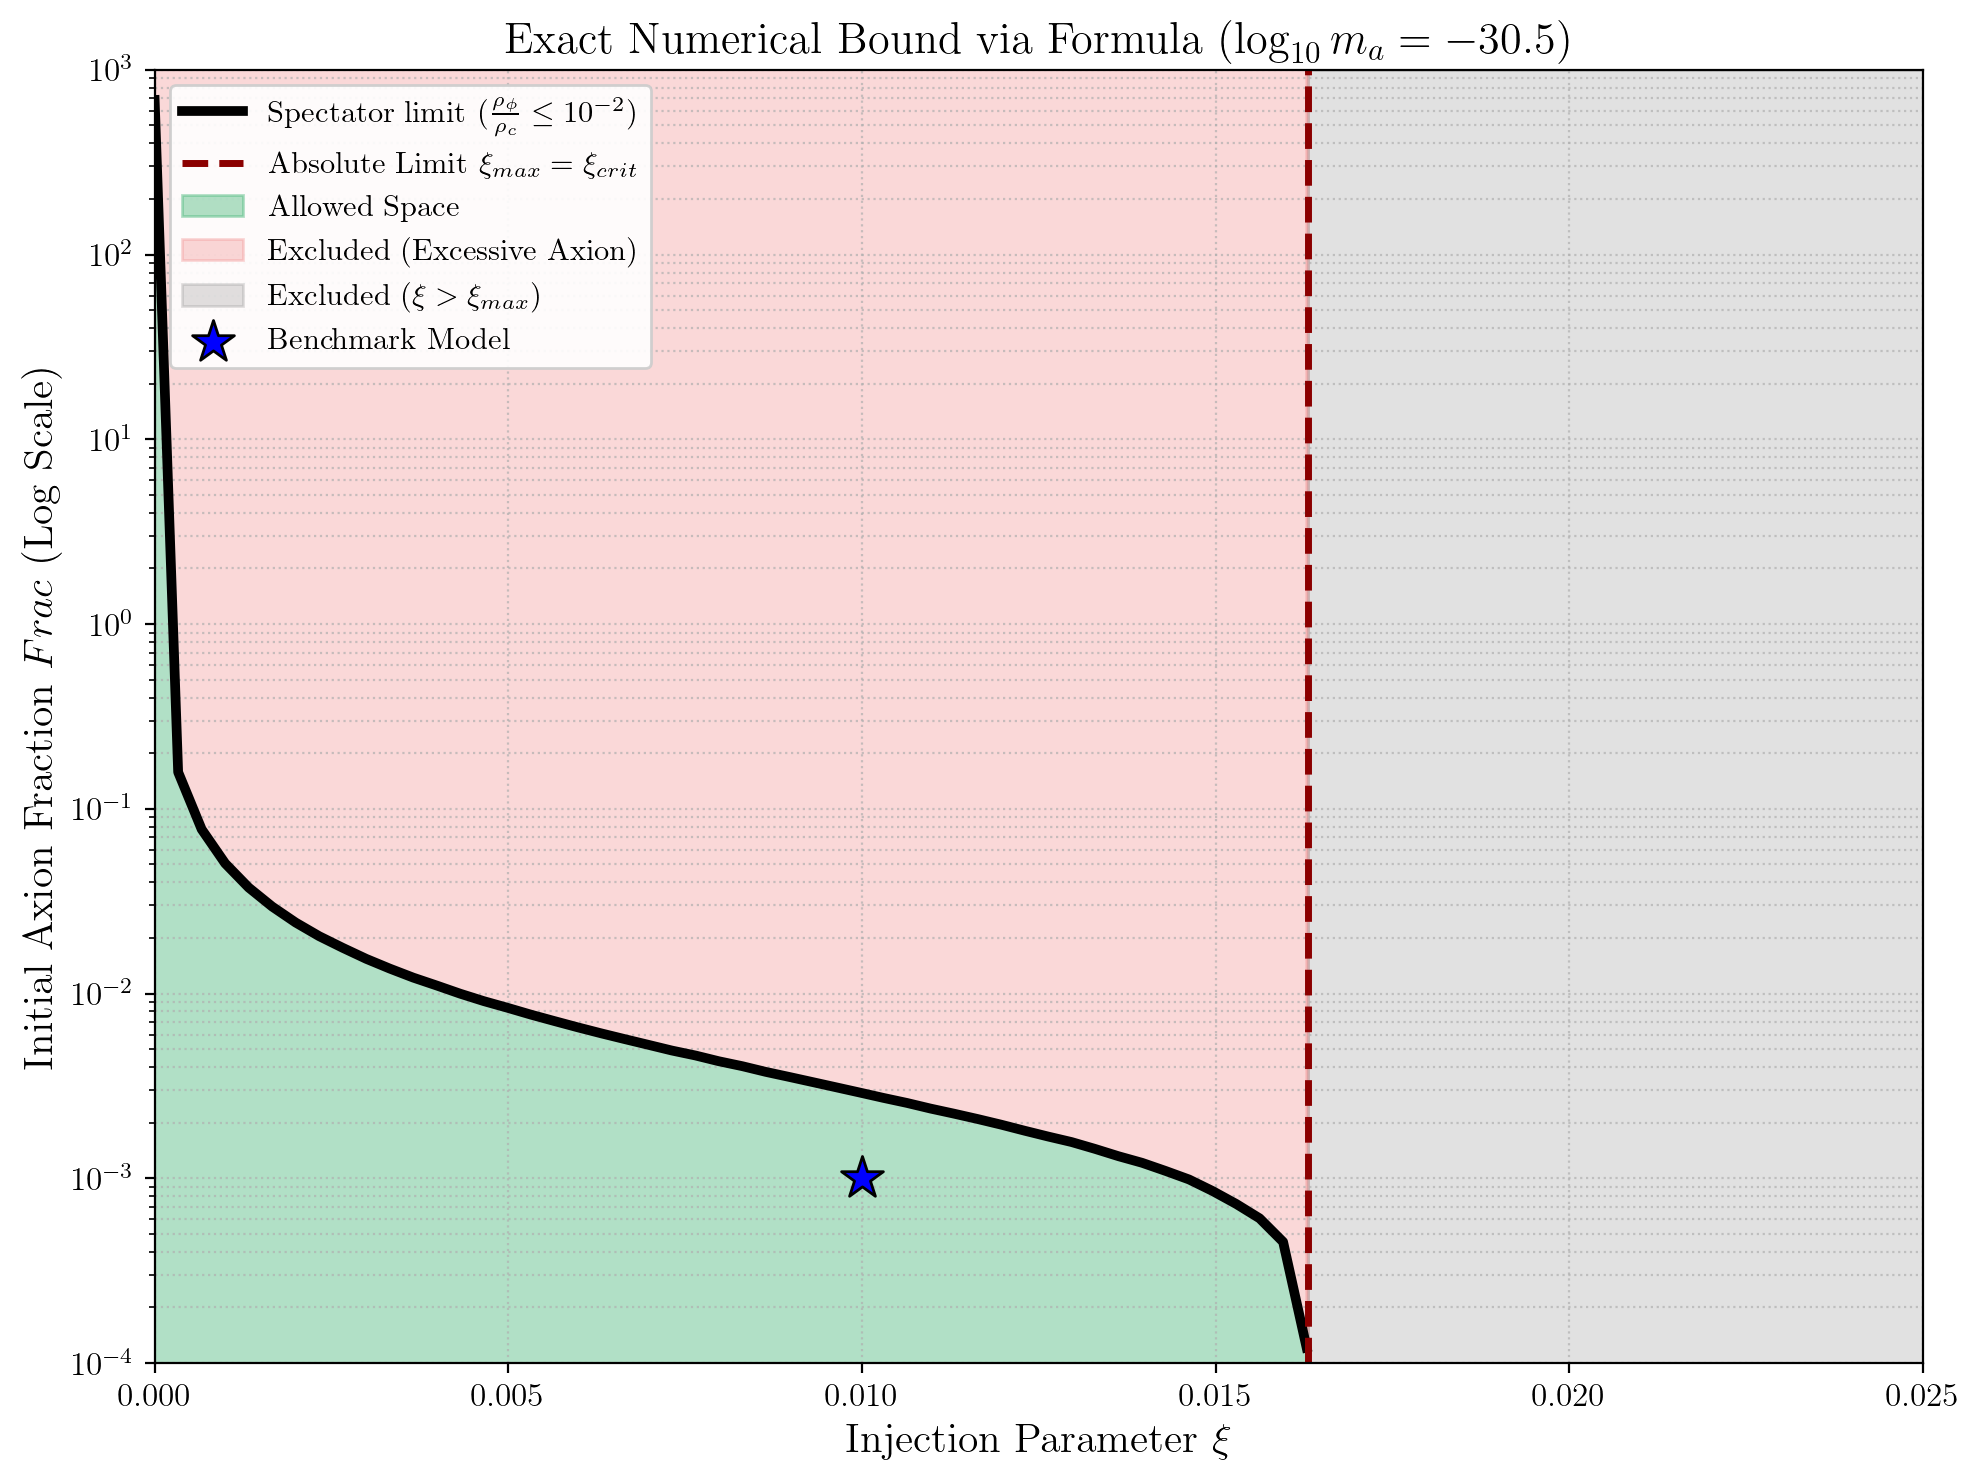

In [25]:
# ==============================================================================
# EXACT NUMERICAL EXCLUSION PLOT (VIA EXPLICIT ANALYTICAL-HYBRID FORMULA)
# ==============================================================================

# --- 1. Setup Numerical Grid ---
N_pts = 50  
# We stop at 99.5% of xi_max to avoid solver stalling at the exact potential peak
xi_num_vals = np.linspace(0.0, true_xi_max * 0.999, N_pts)
Frac_max_formula = np.zeros(N_pts)

# Pre-calculate baseline potential for normalization (rho_phi_ini)
V_ini_local = local.V_phi(1.0, logm, tf, n, deriv=0)
H_a = local.H0Mpc * np.array([local.Ea(a_val) for a_val in a])

print(f"Running exclusion plot via Explicit Formula for {N_pts} points...")
print(f"(Global settings: logm = {logm}, xi_max = {true_xi_max:.5f})")

# --- 2. Numerical Scan & Formula Application ---
for idx, xi_val in enumerate(xi_num_vals):
    
    # A. Run exact IVP solver to extract axion dynamics
    phi = solve_ivp(local.EoM_phi, [a[0], 1.0], [bphi0_ini, bphi1_ini], 
                    t_eval=a, args=[logm, tf, n, xi_val, eps, z_start, z_end, bphi0_ini], 
                    atol=atol, rtol=rtol, method="RK45")
    
    x0 = phi['y'][0]  
    x1 = phi['y'][1]  
    
    # Compute Axion Energy Density (rho_phi)
    K_local = 0.5 * (a * H_a * x1)**2
    V_local = np.array([local.V_phi(val, logm, tf, n, deriv=0) for val in x0])
    rho_phi_local = K_local + V_local
    
    # EXACT FORMULA TERM: rho_phi(a) / rho_phi_ini
    axion_norm_evol = rho_phi_local / V_ini_local
    
    # B. Compute Exact CDM Density Modification R(a)
    R_a = np.ones_like(a)
    mask_phase2 = (a >= a_start) & (a <= a_end)
    mask_phase3 = a > a_end
    
    R_a[mask_phase2] = (a[mask_phase2] / a_start)**(-xi_val)
    R_a[mask_phase3] = (a_end / a_start)**(-xi_val)
    
    # C. EXPLICIT FORMULA COMPUTATION
    # Transfer Function = R(a)^-1 * a^3 * (rho_phi(a) / rho_phi_ini)
    transfer_func = (1.0 / R_a) * (a**3.0) * axion_norm_evol
    
    # Extract the asymptotic value today (a -> 1)
    transfer_plateau = transfer_func[-1]
    
    # D. INVERSION FOR EXCLUSION BOUND
    # Spectator Limit: Frac_max * transfer_plateau = 10^-2
    Frac_max_formula[idx] = 0.01 / transfer_plateau

print("Scan completed! Plotting...")

# --- 3. Plotting the Exact Exclusion Boundary ---
fig, ax = plt.subplots(figsize=(10, 7.5))

# Plot the Boundary derived from the explicit formula
ax.plot(xi_num_vals, Frac_max_formula, color='black', linewidth=3.5, 
        label=r'Spectator limit ($\frac{\rho_{\phi}}{\rho_c} \le 10^{-2}$)')

# Plot the Dynamical/Background Wall
ax.axvline(true_xi_max, color='darkred', linestyle='--', linewidth=2.5, 
           label=rf'Absolute Limit $\xi_{{max}} = \xi_{{crit}}$')

# Shading Allowed vs Excluded Regions
ax.fill_between(xi_num_vals, 1e-10, Frac_max_formula, 
                color='mediumseagreen', alpha=0.4, label='Allowed Space')

ax.fill_between(xi_num_vals, Frac_max_formula, 1e6, 
                color='lightcoral', alpha=0.3, label='Excluded (Excessive Axion)')

# Shading for the Broken Dynamics Wall
ax.axvspan(xi_num_vals[-1], true_xi_max, color='lightcoral', alpha=0.3)
ax.axvspan(true_xi_max, 0.025, color='dimgray', alpha=0.2, 
           label=r'Excluded ($\xi > \xi_{max}$)')

# Add Benchmark Point
benchmark_xi = 0.01
benchmark_frac = 1e-3
ax.scatter([benchmark_xi], [benchmark_frac], color='blue', s=250, marker='*', zorder=5, 
           edgecolor='black', label=r'Benchmark Model')

# Formatting
ax.set_xlim(0.0, 0.025)
ax.set_yscale('log')
ax.set_ylim(1e-4, 1e3) 

ax.set_xlabel(r'Injection Parameter $\xi$', fontsize=15)
ax.set_ylabel(r'Initial Axion Fraction $Frac$ (Log Scale)', fontsize=15)
ax.set_title(rf'Exact Numerical Bound via Formula ($\log_{{10}} m_a = {logm}$)', fontsize=16, fontweight='bold')

# Clean legend
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, fontsize=11, loc='upper left', framealpha=0.9)

ax.grid(True, which='both', linestyle=':', alpha=0.7)
ax.tick_params(axis='both', which='major', labelsize=12)

plt.tight_layout()
plt.show()